# 02 Feature study and ensembles

Uses the cleaned windows from notebook 01. The image and PV CNN is retrained with one feature group added at a time (same data, validation days and seed), the configuration with the lowest validation loss is trained with five seeds as a deep ensemble, and MC dropout is added. The notebook also writes `clock_fix.json`, and reports results by weather type with day-level bootstrap intervals.

In [17]:
!pip install -q datasets pvlib
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/UROP'
LOCAL_CACHE = '/content/skippd_cache'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
import os, shutil, time, math, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

os.makedirs(f'{OUT}/figs', exist_ok=True); os.makedirs(f'{OUT}/ckpt', exist_ok=True)
os.makedirs(f'{OUT}/cache', exist_ok=True); os.makedirs(LOCAL_CACHE, exist_ok=True)
SEED = 42
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', device)

device: cuda


In [19]:
INPUT_LEN, HORIZON = 15, 15
LAT, LON, ALT = 37.4275, -122.1697, 23
PANEL_TILT, PANEL_AZIMUTH, PANEL_KW_DC = 22.5, 195, 30.1
PV_CAP_PCT = 99.95
RUN = 'feat'

TRAIN = dict(batch=256, lr=1e-3, max_epochs=25, patience=4, val_frac_days=0.15)
ENSEMBLE_SEEDS = [0, 1, 2, 3, 4]
MC_PASSES = 30

ABLATION = [
    ('A0 baseline (PV history + image)',      dict()),
    ('A1 + time and sun position',            dict(geo=True)),
    ('A2 + clear-sky PV',                     dict(geo=True, cs=True)),
    ('A3 + predict clear-sky index',          dict(geo=True, cs=True, kout=True)),
    ('A4 + PV variability',                   dict(geo=True, cs=True, kout=True, var=True)),
    ('A5 + cloud motion (frame difference)',  dict(geo=True, cs=True, kout=True, var=True, motion=True)),
]

RESULTS_CSV = f'{OUT}/results.csv'
RESULT_COLS = ['when','run','train_data','test_set','model','n','rmse','mae','skill_rmse_vs_smart','skill_mae_vs_smart','notes']
def log_result(**row):
    row['when'] = pd.Timestamp.now().isoformat(timespec='seconds')
    pd.DataFrame([{c: row.get(c, '') for c in RESULT_COLS}]).to_csv(RESULTS_CSV, mode='a', header=not os.path.exists(RESULTS_CSV), index=False)
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items() if k not in ('when', 'run')})

## 1. Data and clock correction

In [20]:
def load_split(split):
    names = ['img', 'pv', 'ts']
    local = {k: f'{LOCAL_CACHE}/{split}_{k}.npy' for k in names}
    drive_ = {k: f'{OUT}/cache/{split}_{k}.npy' for k in names}

    if not all(os.path.exists(p) for p in local.values()) and all(os.path.exists(p) for p in drive_.values()):
        print(f'[{split}] copying cache from Drive to local disk...')
        for k in names: shutil.copy(drive_[k], local[k])

    if all(os.path.exists(p) for p in local.values()):
        print(f'[{split}] loading from cache')
        img = np.load(local['img']); pv = np.load(local['pv']); ts_raw = np.load(local['ts'])
    else:
        from datasets import load_dataset
        print(f'[{split}] downloading from Hugging Face (first run only)...')
        ds = load_dataset('solarbench/SKIPPD', split=split)
        n = len(ds)
        img = np.empty((n, 64, 64, 3), dtype=np.uint8)
        pos = 0
        t0 = time.time()
        for b in ds.iter(batch_size=2000):
            arr = np.stack([np.asarray(im.convert('RGB')) for im in b['image']])
            img[pos:pos + len(arr)] = arr
            pos += len(arr)
            if pos % 50000 < 2000: print(f'  {pos}/{n} images  ({time.time()-t0:.0f}s)')
        pv = np.asarray(ds['pv'], dtype=np.float32)
        t = pd.to_datetime(ds['time'])
        if t.tz is not None:
            t = t.tz_convert('UTC').tz_localize(None)
        ts_raw = t.values.astype('datetime64[ns]')
        for k, v in [('img', img), ('pv', pv), ('ts', ts_raw)]:
            np.save(local[k], v); shutil.copy(local[k], drive_[k])
        print(f'[{split}] cached to Drive')

    order = np.argsort(ts_raw, kind='stable')
    return dict(name=split, img=img, img_idx=order, pv=pv[order].astype(np.float32),
                ts=pd.DatetimeIndex(ts_raw[order]))

In [21]:
TR = load_split('train'); TE = load_split('test')
prep_path = f'{OUT}/day1b_prep.npz'
assert os.path.exists(prep_path), 'Run notebook 01 first: it creates day1b_prep.npz'
P = np.load(prep_path, allow_pickle=True)
TR['w_clean'] = P['tr_w_clean']; TE['w_clean'] = P['te_w_clean']; TE['w_raw'] = P['te_w_raw']
print('train clean windows:', len(TR['w_clean']), '| test clean:', len(TE['w_clean']), '| test raw:', len(TE['w_raw']))

[train] loading from cache
[test] loading from cache
train clean windows: 320172 | test clean: 12777 | test raw: 13392


In [22]:
from pvlib.location import Location
from pvlib import irradiance
SITE = Location(LAT, LON, altitude=ALT)
TZ = 'UTC'

def solar_terms(ts_naive, tz='UTC'):
    idx = pd.DatetimeIndex(ts_naive)
    aware = idx.tz_localize('UTC') if tz == 'UTC' else idx.tz_localize(tz, ambiguous='NaT', nonexistent='NaT')
    ok = ~aware.isna()
    out = [np.full(len(idx), np.nan, dtype=np.float32) for _ in range(3)]
    a = aware[ok]
    cs = SITE.get_clearsky(a, model='ineichen'); sp = SITE.get_solarposition(a)
    poa = irradiance.get_total_irradiance(PANEL_TILT, PANEL_AZIMUTH, dni=cs['dni'], ghi=cs['ghi'], dhi=cs['dhi'],
                                          solar_zenith=sp['apparent_zenith'], solar_azimuth=sp['azimuth'])
    out[0][ok] = np.clip(PANEL_KW_DC * poa['poa_global'].values / 1000.0, 0, PANEL_KW_DC)
    out[1][ok] = sp['apparent_zenith'].values
    out[2][ok] = sp['azimuth'].values
    return out

def local_date(ts):
    return np.array((pd.DatetimeIndex(ts) - pd.Timedelta(hours=8)).date)

def is_dst(d):
    return bool((pd.Timestamp(d) + pd.Timedelta(hours=12)).tz_localize('America/Los_Angeles').dst())

FIX_PATH = f'{OUT}/clock_fix.json'
if os.path.exists(FIX_PATH):
    CLOCK_FIX = json.load(open(FIX_PATH)); print('clock fix loaded:', CLOCK_FIX)
else:
    ld = local_date(TR['ts'])
    df = pd.DataFrame({'pv': TR['pv'], 'd': ld}, index=TR['ts'])
    rough = {d: np.abs(np.diff(g.pv.values)).sum() / max(g.pv.sum(), 1e-6)
             for d, g in df.groupby('d') if len(g) >= 300 and g.pv.max() >= 15}
    rough = pd.Series(rough).sort_values()
    picks = pd.DataFrame({'day': rough.index}).assign(m=lambda x: [(d.year, d.month) for d in x.day]).groupby('m').head(3).day
    rows = []
    for d in picks:
        p = df.pv[ld == d]; p.index = p.index.floor('min'); p = p[~p.index.duplicated()]
        grid = pd.date_range(p.index.min() - pd.Timedelta(minutes=150), p.index.max() + pd.Timedelta(minutes=150), freq='1min')
        cs = pd.Series(solar_terms(grid)[0], index=grid); pv_g = p.reindex(grid)
        best = (0, -2.0)
        for L in range(-120, 125, 5):
            c = cs.shift(L); ok = pv_g.notna() & c.notna()
            if ok.sum() < 100: continue
            r = np.corrcoef(pv_g[ok], c[ok])[0, 1]
            if r > best[1]: best = (L, r)
        rows.append(dict(day=d, dst=is_dst(d), lag=best[0], corr=best[1]))
    lag = pd.DataFrame(rows); good = lag[lag['corr'] >= 0.95]
    m_dst, m_std = good[good.dst].lag.median(), good[~good.dst].lag.median()
    print(f'{len(good)}/{len(lag)} clear days usable. Median shift: daylight saving {m_dst} min, standard {m_std} min')
    std = int(5 * round(m_std / 5)) if abs(m_std) >= 15 else 0
    CLOCK_FIX = {'dst_min': std + 60 * int(round((m_dst - m_std) / 60)), 'std_min': std}
    json.dump(CLOCK_FIX, open(FIX_PATH, 'w')); lag.to_csv(f'{OUT}/clock_offset_by_day_v2.csv', index=False)
    print('clock fix:', CLOCK_FIX)

def solar_time(ts):
    ts = pd.DatetimeIndex(ts); ld = local_date(ts)
    lut = {d: is_dst(d) for d in set(ld)}
    shift = np.where(np.array([lut[d] for d in ld]), CLOCK_FIX['dst_min'], CLOCK_FIX['std_min'])
    return ts - pd.to_timedelta(shift, unit='min')

for D in (TR, TE):
    cs, zen, azi = solar_terms(solar_time(D['ts']))
    D['cs_raw'] = np.nan_to_num(cs); D['zen'] = np.nan_to_num(zen, nan=180.0); D['azi'] = np.nan_to_num(azi)
PV_CAP = float(np.percentile(TR['pv'], PV_CAP_PCT))
for D in (TR, TE):
    D['cs'] = np.minimum(D['cs_raw'], PV_CAP).astype(np.float32)
    D['k'] = np.clip(D['pv'] / np.maximum(D['cs'], 1.0), 0, 1.5).astype(np.float32)
    doy = D['ts'].dayofyear.values
    D['doy_s'] = np.sin(2 * np.pi * doy / 365.25).astype(np.float32); D['doy_c'] = np.cos(2 * np.pi * doy / 365.25).astype(np.float32)
    D['ld'] = local_date(D['ts'])
print(f'PV cap (inverter limit estimate): {PV_CAP:.2f} kW')

clock fix loaded: {'dst_min': 60, 'std_min': 0}
PV cap (inverter limit estimate): 28.91 kW


## 2. Baselines

In [23]:
def metrics(pred, true):
    return float(np.sqrt(np.mean((pred - true) ** 2))), float(np.mean(np.abs(pred - true)))

PRED = {}
SIGMA = {}
TESTS = {'raw test': TE['w_raw'], 'clean test': TE['w_clean']}
for label, w in TESTS.items():
    last = TE['pv'][w]
    PRED[('naive persistence', label)] = last
    PRED[('smart persistence', label)] = np.clip(last / np.maximum(TE['cs_raw'][w], 1e-3) * TE['cs_raw'][w + HORIZON], 0, None)
BASE = {label: metrics(PRED[('smart persistence', label)], TE['pv'][w + HORIZON]) for label, w in TESTS.items()}
for label, (r, m) in BASE.items(): print(f'smart persistence on {label}: RMSE {r:.3f}  MAE {m:.3f}')

def score(name, notes=''):
    for label, w in TESTS.items():
        y = TE['pv'][w + HORIZON]; r, m = metrics(PRED[(name, label)], y); r_s, m_s = BASE[label]
        log_result(run=RUN, train_data='clean', test_set=label, model=name, n=len(y), rmse=r, mae=m,
                   skill_rmse_vs_smart=1 - r / r_s, skill_mae_vs_smart=1 - m / m_s, notes=notes)
score('naive persistence'); score('smart persistence')

smart persistence on raw test: RMSE 3.609  MAE 1.634
smart persistence on clean test: RMSE 3.233  MAE 1.474
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'naive persistence', 'n': 13392, 'rmse': 3.743, 'mae': 2.145, 'skill_rmse_vs_smart': -0.037, 'skill_mae_vs_smart': -0.313, 'notes': ''}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'naive persistence', 'n': 12777, 'rmse': 3.375, 'mae': 1.982, 'skill_rmse_vs_smart': -0.044, 'skill_mae_vs_smart': -0.344, 'notes': ''}
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'smart persistence', 'n': 13392, 'rmse': 3.609, 'mae': 1.634, 'skill_rmse_vs_smart': 0.0, 'skill_mae_vs_smart': 0.0, 'notes': ''}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'smart persistence', 'n': 12777, 'rmse': 3.233, 'mae': 1.474, 'skill_rmse_vs_smart': 0.0, 'skill_mae_vs_smart': 0.0, 'notes': ''}


## 3. Features and model

In [24]:
OFF = np.arange(-(INPUT_LEN - 1), 1)

def vec_feats(D, t, c):
    H = t[:, None] + OFF; tg = t + HORIZON
    parts = [D['pv'][H] / PV_CAP]
    if c.get('geo'):
        parts.append(np.stack([D['doy_s'][t], D['doy_c'][t], D['zen'][t] / 90, D['zen'][tg] / 90,
                               np.cos(np.radians(D['zen'][t])), np.sin(np.radians(D['azi'][t])), np.cos(np.radians(D['azi'][t]))], 1))
    if c.get('cs'):
        parts += [D['cs'][H] / PV_CAP, (D['cs'][tg] / PV_CAP)[:, None]]
    if c.get('kout'):
        parts.append(D['k'][H])
    if c.get('var'):
        kh, ph = D['k'][H], D['pv'][H]
        parts.append(np.stack([kh.std(1), np.abs(np.diff(ph, axis=1)).mean(1) / PV_CAP,
                               (ph[:, -1] - ph[:, -6]) / PV_CAP, (ph.max(1) - ph.min(1)) / PV_CAP], 1))
    return np.concatenate(parts, 1).astype(np.float32)

def to_img(D, t):
    return torch.from_numpy(D['img'][D['img_idx'][t]]).to(device).permute(0, 3, 1, 2).float().div_(255.0)

def batches(D, w, c, bs, shuffle, rng=None):
    idx = rng.permutation(len(w)) if shuffle else np.arange(len(w))
    for i in range(0, len(w), bs):
        t = w[idx[i:i + bs]]
        xv = torch.from_numpy(vec_feats(D, t, c)).to(device)
        img = to_img(D, t)
        if c.get('motion'): img = torch.cat([img, img - to_img(D, t - 5)], 1)
        cst = torch.from_numpy(D['cs'][t + HORIZON] / PV_CAP).float().to(device)
        y = torch.from_numpy(D['pv'][t + HORIZON] / PV_CAP).float().to(device)
        yield xv, img, cst, y

class FeatCNN(nn.Module):
    '''Same image branch as the notebook 01 CNN; the PV branch takes the extra feature vector.
       With kout=True it outputs a clear-sky index and the forecast is index x clear-sky PV at the target time.'''
    def __init__(self, n_vec, img_ch=3, use_image=True, kout=False, p_drop=0.2):
        super().__init__()
        self.use_image, self.kout = use_image, kout
        if use_image:
            self.conv = nn.Sequential(
                nn.Conv2d(img_ch, 16, 5, stride=2, padding=2), nn.ReLU(),
                nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
                nn.Conv2d(32, 32, 3, stride=2, padding=1), nn.ReLU(),
                nn.AdaptiveAvgPool2d(4))
        self.vec = nn.Sequential(nn.Linear(n_vec, 64), nn.ReLU(), nn.Linear(64, 32), nn.ReLU())
        self.head = nn.Sequential(nn.Linear((32 * 16 if use_image else 0) + 32, 64), nn.ReLU(), nn.Dropout(p_drop), nn.Linear(64, 1))
    def forward(self, xv, img, cst):
        f = self.vec(xv)
        if self.use_image: f = torch.cat([self.conv(img).flatten(1), f], 1)
        out = self.head(f).squeeze(-1)
        return out * cst if self.kout else out

def n_vec(c):
    return vec_feats(TR, TR['w_clean'][:2], c).shape[1]

def split_by_days(D, w, frac, seed=SEED):
    days = D['ld'][w]; uniq = np.array(sorted(set(days)))
    val_days = set(np.random.default_rng(seed).choice(uniq, int(len(uniq) * frac), replace=False))
    m = pd.Series(days).isin(val_days).values
    return w[~m], w[m]
W_TR, W_VA = split_by_days(TR, TR['w_clean'], TRAIN['val_frac_days'])
print(f'{len(W_TR)} train / {len(W_VA)} val windows (validation = random 15% of days, same as notebook 01)')

271661 train / 48511 val windows (validation = random 15% of days, same as notebook 01)


In [25]:
def train_run(tag, c, seed=0, use_image=True, cfg=TRAIN):
    ck = f'{OUT}/ckpt/{RUN}_{tag}.pt'
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    model = FeatCNN(n_vec(c), img_ch=6 if c.get('motion') else 3, use_image=use_image, kout=bool(c.get('kout'))).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=1e-4)
    st = dict(epoch=0, best=float('inf'), bad=0, hist=[], best_state=None, done=False)
    if os.path.exists(ck):
        st = torch.load(ck, map_location=device, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt'])
        if not st.get('done'): print(f'[{tag}] resuming from epoch {st["epoch"]}')
    loss_fn = nn.MSELoss()
    while not st.get('done'):
        t0 = time.time(); model.train(); tl = []
        for xv, img, cst, y in batches(TR, W_TR, c, cfg['batch'], True, rng):
            loss = loss_fn(model(xv, img, cst), y); opt.zero_grad(); loss.backward(); opt.step(); tl.append(loss.item())
        model.eval(); vs, vn = 0.0, 0
        with torch.no_grad():
            for xv, img, cst, y in batches(TR, W_VA, c, 2048, False):
                vs += loss_fn(model(xv, img, cst), y).item() * len(y); vn += len(y)
        v = vs / vn; st['hist'].append((float(np.mean(tl)), v)); st['epoch'] += 1
        if v < st['best']:
            st['best'], st['bad'] = v, 0
            st['best_state'] = {k: x.detach().clone() for k, x in model.state_dict().items()}
        else:
            st['bad'] += 1
        st['done'] = st['epoch'] >= cfg['max_epochs'] or st['bad'] >= cfg['patience']
        st['model'], st['opt'] = model.state_dict(), opt.state_dict()
        torch.save(st, ck)
        print(f'[{tag}] epoch {st["epoch"]:2d}  train {np.mean(tl):.4f}  val {v:.4f}  ({time.time()-t0:.0f}s)')
    model.load_state_dict(st['best_state']); model.eval()
    return model, st

@torch.no_grad()
def predict(model, D, w, c, mc_passes=0):
    if mc_passes: model.train()
    mean, std = [], []
    for xv, img, cst, _ in batches(D, w, c, 2048, False):
        if mc_passes:
            s = torch.stack([model(xv, img, cst) for _ in range(mc_passes)])
            mean.append(s.mean(0).cpu().numpy()); std.append(s.std(0).cpu().numpy())
        else:
            mean.append(model(xv, img, cst).cpu().numpy())
    model.eval()
    m = np.concatenate(mean) * PV_CAP
    return (m, np.concatenate(std) * PV_CAP) if mc_passes else m

## 4. Feature study

In [26]:
ABL = []
for name, c in ABLATION:
    tag = name.split()[0]
    model, st = train_run(tag, c, seed=0)
    for label, w in TESTS.items(): PRED[(name, label)] = predict(model, TE, w, c)
    score(name, notes=f'val_mse={st["best"]:.5f}')
    ABL.append(dict(config=name, val_mse=st['best'], epochs=st['epoch']))
    del model; torch.cuda.empty_cache()
abl = pd.DataFrame(ABL)
best_name = abl.sort_values('val_mse').iloc[0].config
BEST_C = dict(ABLATION)[best_name]
print('\nBest configuration by VALIDATION loss:', best_name)
abl.to_csv(f'{OUT}/feat_ablation_val.csv', index=False)

{'train_data': 'clean', 'test_set': 'raw test', 'model': 'A0 baseline (PV history + image)', 'n': 13392, 'rmse': 3.076, 'mae': 1.698, 'skill_rmse_vs_smart': 0.148, 'skill_mae_vs_smart': -0.039, 'notes': 'val_mse=0.00435'}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'A0 baseline (PV history + image)', 'n': 12777, 'rmse': 2.838, 'mae': 1.574, 'skill_rmse_vs_smart': 0.122, 'skill_mae_vs_smart': -0.067, 'notes': 'val_mse=0.00435'}
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'A1 + time and sun position', 'n': 13392, 'rmse': 3.038, 'mae': 1.748, 'skill_rmse_vs_smart': 0.158, 'skill_mae_vs_smart': -0.07, 'notes': 'val_mse=0.00413'}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'A1 + time and sun position', 'n': 12777, 'rmse': 2.815, 'mae': 1.64, 'skill_rmse_vs_smart': 0.129, 'skill_mae_vs_smart': -0.112, 'notes': 'val_mse=0.00413'}
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'A2 + clear-sky PV', 'n': 13392, 'rmse': 2.981, 'mae': 1.672, 'sk

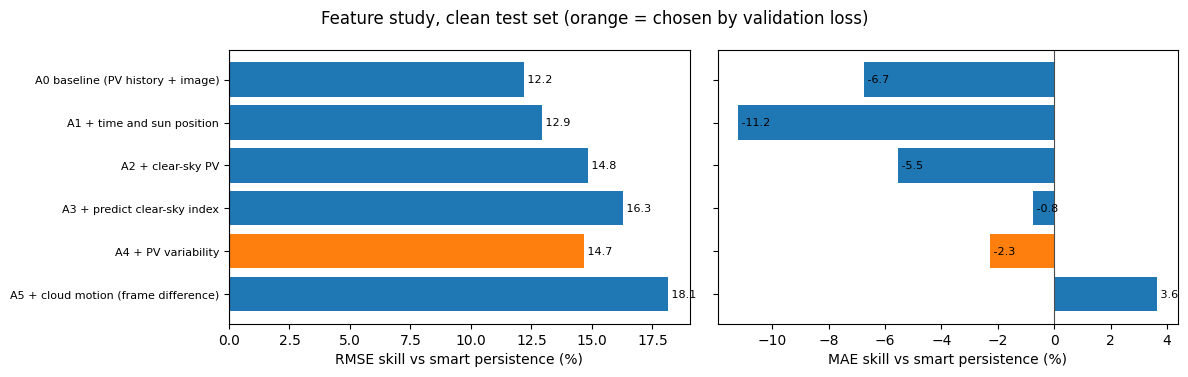

                               model  rmse   mae  skill_rmse_vs_smart  skill_mae_vs_smart
                   naive persistence 3.375 1.982               -0.044              -0.344
                   smart persistence 3.233 1.474                0.000               0.000
    A0 baseline (PV history + image) 2.838 1.574                0.122              -0.067
          A1 + time and sun position 2.815 1.640                0.129              -0.112
                   A2 + clear-sky PV 2.753 1.556                0.148              -0.055
        A3 + predict clear-sky index 2.707 1.486                0.163              -0.008
                 A4 + PV variability 2.759 1.508                0.147              -0.023
A5 + cloud motion (frame difference) 2.647 1.421                0.181               0.036


In [27]:
res = pd.read_csv(RESULTS_CSV); res = res[res.run == RUN].drop_duplicates(['test_set', 'model'], keep='last')
names = [n for n, _ in ABLATION]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, metric, lab in [(axes[0], 'skill_rmse_vs_smart', 'RMSE skill vs smart persistence'), (axes[1], 'skill_mae_vs_smart', 'MAE skill vs smart persistence')]:
    q = res[(res.test_set == 'clean test') & res.model.isin(names)].set_index('model').loc[names]
    ax.barh(range(len(names)), q[metric] * 100, color=['C0' if n != best_name else 'C1' for n in names])
    ax.axvline(0, color='0.3', lw=.8); ax.set_xlabel(lab + ' (%)')
    for i, v in enumerate(q[metric] * 100): ax.text(v, i, f' {v:.1f}', va='center', fontsize=8)
axes[0].set_yticks(range(len(names))); axes[0].set_yticklabels(names, fontsize=8); axes[0].invert_yaxis()
fig.suptitle('Feature study, clean test set (orange = chosen by validation loss)'); fig.tight_layout()
fig.savefig(f'{OUT}/figs/feat_ablation.png', dpi=150); plt.show()
print(res[(res.test_set == 'clean test') & res.model.isin(names + ['smart persistence', 'naive persistence'])][['model', 'rmse', 'mae', 'skill_rmse_vs_smart', 'skill_mae_vs_smart']].round(3).to_string(index=False))

## 5. Five seeds, deep ensemble, MC dropout and PV-only model

In [28]:
best_tag = best_name.split()[0]
members = {}
for s in ENSEMBLE_SEEDS:
    tag = best_tag if s == 0 else f'{best_tag}_seed{s}'
    m, _ = train_run(tag, BEST_C, seed=s)
    members[s] = {label: predict(m, TE, w, BEST_C) for label, w in TESTS.items()}
    if s == 0:
        for label, w in TESTS.items():
            PRED[('MC dropout', label)], SIGMA[('MC dropout', label)] = predict(m, TE, w, BEST_C, mc_passes=MC_PASSES)
    del m; torch.cuda.empty_cache()

seed_rows = []
for label, w in TESTS.items():
    y = TE['pv'][w + HORIZON]
    stack = np.stack([members[s][label] for s in ENSEMBLE_SEEDS])
    PRED[('deep ensemble (5 seeds)', label)] = stack.mean(0); SIGMA[('deep ensemble (5 seeds)', label)] = stack.std(0)
    r = [metrics(p, y) for p in stack]
    seed_rows.append(dict(test_set=label, rmse_mean=np.mean([a for a, _ in r]), rmse_std=np.std([a for a, _ in r]),
                          mae_mean=np.mean([b for _, b in r]), mae_std=np.std([b for _, b in r])))
seed_tbl = pd.DataFrame(seed_rows); print('Single models across 5 seeds (mean ± std):'); print(seed_tbl.round(3).to_string(index=False))
seed_tbl.to_csv(f'{OUT}/feat_seed_variation.csv', index=False)
score('deep ensemble (5 seeds)', notes=best_name); score('MC dropout', notes=best_name)

m, _ = train_run(f'{best_tag}_pvonly', BEST_C, seed=0, use_image=False)
for label, w in TESTS.items(): PRED[('best features, PV only', label)] = predict(m, TE, w, BEST_C)
score('best features, PV only', notes=best_name); del m

Single models across 5 seeds (mean ± std):
  test_set  rmse_mean  rmse_std  mae_mean  mae_std
  raw test      2.983     0.017     1.632    0.027
clean test      2.736     0.024     1.514    0.029
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'deep ensemble (5 seeds)', 'n': 13392, 'rmse': 2.943, 'mae': 1.575, 'skill_rmse_vs_smart': 0.185, 'skill_mae_vs_smart': 0.036, 'notes': 'A4 + PV variability'}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'deep ensemble (5 seeds)', 'n': 12777, 'rmse': 2.698, 'mae': 1.456, 'skill_rmse_vs_smart': 0.166, 'skill_mae_vs_smart': 0.013, 'notes': 'A4 + PV variability'}
{'train_data': 'clean', 'test_set': 'raw test', 'model': 'MC dropout', 'n': 13392, 'rmse': 3.005, 'mae': 1.629, 'skill_rmse_vs_smart': 0.167, 'skill_mae_vs_smart': 0.003, 'notes': 'A4 + PV variability'}
{'train_data': 'clean', 'test_set': 'clean test', 'model': 'MC dropout', 'n': 12777, 'rmse': 2.76, 'mae': 1.511, 'skill_rmse_vs_smart': 0.146, 'skill_mae_vs_smart': -0

In [29]:
def crps_gauss(mu, sig, y):
    sig = np.maximum(sig, 1e-6); z = (y - mu) / sig
    from math import pi
    pdf = np.exp(-0.5 * z ** 2) / np.sqrt(2 * pi); cdf = 0.5 * (1 + np.vectorize(math.erf)(z / np.sqrt(2)))
    return float(np.mean(sig * (z * (2 * cdf - 1) + 2 * pdf - 1 / np.sqrt(pi))))

U = []
for name in ['deep ensemble (5 seeds)', 'MC dropout']:
    for label, w in TESTS.items():
        y = TE['pv'][w + HORIZON]; mu, sig = PRED[(name, label)], SIGMA[(name, label)]
        cov = float(np.mean(np.abs(y - mu) <= 1.645 * sig))
        U.append(dict(model=name, test_set=label, crps=crps_gauss(mu, sig, y), coverage_90=cov, mean_width_90=float(np.mean(2 * 1.645 * sig))))
unc = pd.DataFrame(U); print(unc.round(3).to_string(index=False)); unc.to_csv(f'{OUT}/feat_uncertainty.csv', index=False)
print('Target coverage is 0.90. Below = overconfident (intervals too narrow).')

                  model   test_set  crps  coverage_90  mean_width_90
deep ensemble (5 seeds)   raw test 1.416        0.469          1.251
deep ensemble (5 seeds) clean test 1.305        0.482          1.212
             MC dropout   raw test 1.483        0.494          1.311
             MC dropout clean test 1.369        0.505          1.308
Target coverage is 0.90. Below = overconfident (intervals too narrow).


## 6. Results by weather and bootstrap intervals

Test days per weather type: {'clear': 10, 'partly cloudy': 9, 'overcast': 1}
weather                           clear  overcast  partly cloudy
model                                                           
smart persistence                 0.232     3.230          4.718
A0 baseline (PV history + image)  0.560     3.403          4.069
A4 + PV variability               0.466     3.517          3.952
deep ensemble (5 seeds)           0.398     3.424          3.872


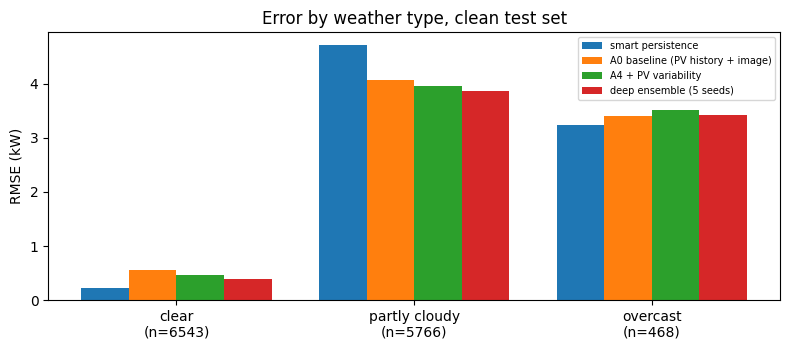

In [30]:
def day_classes(D):
    day = D['zen'] < 80
    df = pd.DataFrame({'d': D['ld'][day], 'pv': D['pv'][day], 'cs': D['cs'][day], 'k': D['k'][day]})
    g = df.groupby('d')
    mean_k = g.pv.sum() / g.cs.sum().clip(lower=1e-6)
    var_k = g.k.apply(lambda s: np.abs(np.diff(s.values)).mean() if len(s) > 1 else np.nan)
    cls = pd.Series(np.where((var_k < 0.01) & (mean_k > 0.7), 'clear', np.where(mean_k < 0.45, 'overcast', 'partly cloudy')), index=mean_k.index)
    return cls, var_k
CLS, VARK = day_classes(TE)
print('Test days per weather type:', CLS.value_counts().to_dict())

label, w = 'clean test', TESTS['clean test']
y = TE['pv'][w + HORIZON]; wcls = pd.Series(TE['ld'][w]).map(CLS).values
show = ['smart persistence', 'A0 baseline (PV history + image)', best_name, 'deep ensemble (5 seeds)']
rows = []
for name in show:
    for k in ['clear', 'partly cloudy', 'overcast']:
        mk = wcls == k
        if mk.sum() == 0: continue
        r, m = metrics(PRED[(name, label)][mk], y[mk])
        rows.append(dict(model=name, weather=k, n=int(mk.sum()), rmse=r, mae=m))
wt = pd.DataFrame(rows); wt.to_csv(f'{OUT}/feat_weather.csv', index=False)
print(wt.pivot(index='model', columns='weather', values='rmse').loc[show].round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6)); kinds = ['clear', 'partly cloudy', 'overcast']; bw = 0.2
for i, name in enumerate(show):
    q = wt[wt.model == name].set_index('weather').reindex(kinds)
    ax.bar(np.arange(3) + (i - 1.5) * bw, q.rmse, bw, label=name)
ax.set_xticks(range(3)); ax.set_xticklabels([f'{k}\n(n={int((wcls == k).sum())})' for k in kinds]); ax.set_ylabel('RMSE (kW)')
ax.set_title('Error by weather type, clean test set'); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(f'{OUT}/figs/feat_weather.png', dpi=150); plt.show()

In [31]:
def boot_ci(name, ref='smart persistence', label='clean test', n=2000, seed=0):
    w = TESTS[label]; y = TE['pv'][w + HORIZON]; days = TE['ld'][w]
    em, er = PRED[(name, label)] - y, PRED[(ref, label)] - y
    df = pd.DataFrame({'d': days, 'sm': em ** 2, 'sr': er ** 2, 'am': np.abs(em), 'ar': np.abs(er)}).groupby('d').agg(['sum', 'count'])
    S = df.xs('sum', axis=1, level=1); N = df[('sm', 'count')].values
    rng = np.random.default_rng(seed); idx = rng.integers(0, len(S), (n, len(S)))
    tot = lambda col: S[col].values[idx].sum(1)
    nn_ = N[idx].sum(1)
    sk_r = 1 - np.sqrt(tot('sm') / nn_) / np.sqrt(tot('sr') / nn_)
    sk_m = 1 - tot('am') / tot('ar')
    return dict(model=name, vs=ref, days=len(S), rmse_skill_lo=np.percentile(sk_r, 2.5), rmse_skill_hi=np.percentile(sk_r, 97.5),
                mae_skill_lo=np.percentile(sk_m, 2.5), mae_skill_hi=np.percentile(sk_m, 97.5),
                p_not_better_rmse=float(np.mean(sk_r <= 0)))
B = [boot_ci(n) for n in ['A0 baseline (PV history + image)', best_name, 'deep ensemble (5 seeds)', 'best features, PV only']]
B.append(boot_ci('deep ensemble (5 seeds)', ref='A0 baseline (PV history + image)'))
bt = pd.DataFrame(B); print(bt.round(3).to_string(index=False)); bt.to_csv(f'{OUT}/feat_bootstrap.csv', index=False)
print('95% intervals from resampling whole test days. If an interval excludes 0, the improvement is unlikely to be luck.')

                           model                               vs  days  rmse_skill_lo  rmse_skill_hi  mae_skill_lo  mae_skill_hi  p_not_better_rmse
A0 baseline (PV history + image)                smart persistence    20          0.062          0.163        -0.223         0.018              0.001
             A4 + PV variability                smart persistence    20          0.088          0.189        -0.174         0.073              0.000
         deep ensemble (5 seeds)                smart persistence    20          0.113          0.207        -0.110         0.094              0.000
          best features, PV only                smart persistence    20          0.089          0.155        -0.163         0.037              0.000
         deep ensemble (5 seeds) A0 baseline (PV history + image)    20          0.027          0.077         0.033         0.136              0.000
95% intervals from resampling whole test days. If an interval excludes 0, the improvement is unlikely to b

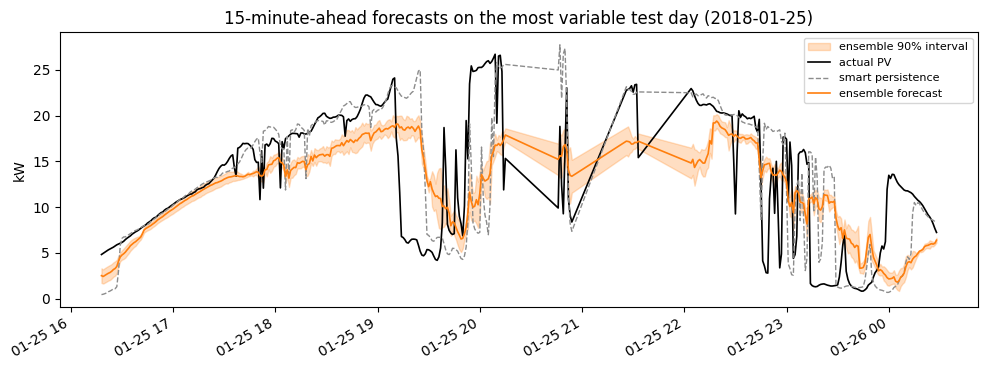

                                            mae                rmse          skill_mae_vs_smart          skill_rmse_vs_smart         
test_set                             clean test raw test clean test raw test         clean test raw test          clean test raw test
model                                                                                                                                
A0 baseline (PV history + image)          1.574    1.698      2.838    3.076             -0.067   -0.039               0.122    0.148
A1 + time and sun position                1.640    1.748      2.815    3.038             -0.112   -0.070               0.129    0.158
A2 + clear-sky PV                         1.556    1.672      2.753    2.981             -0.055   -0.023               0.148    0.174
A3 + predict clear-sky index              1.486    1.607      2.707    2.954             -0.008    0.016               0.163    0.182
A4 + PV variability                       1.508    1.625      

In [32]:
cand = [d for d in VARK.sort_values(ascending=False).index if (TE['ld'][TESTS['clean test']] == d).sum() > 200]
d0 = cand[0]; w = TESTS['clean test']; m = TE['ld'][w] == d0; tt = TE['ts'][w[m] + HORIZON]
mu, sig = PRED[('deep ensemble (5 seeds)', 'clean test')][m], SIGMA[('deep ensemble (5 seeds)', 'clean test')][m]
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(tt, mu - 1.645 * sig, mu + 1.645 * sig, color='C1', alpha=.25, label='ensemble 90% interval')
ax.plot(tt, TE['pv'][w[m] + HORIZON], color='k', lw=1.2, label='actual PV')
ax.plot(tt, PRED[('smart persistence', 'clean test')][m], color='0.55', lw=1, ls='--', label='smart persistence')
ax.plot(tt, mu, color='C1', lw=1.2, label='ensemble forecast')
ax.set_title(f'15-minute-ahead forecasts on the most variable test day ({d0})'); ax.set_ylabel('kW'); ax.legend(fontsize=8)
fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(f'{OUT}/figs/feat_cloudy_day.png', dpi=150); plt.show()

np.savez_compressed(f'{OUT}/feat_preds.npz', best_name=best_name, clock_fix=json.dumps(CLOCK_FIX), pv_cap=PV_CAP,
    **{f'pred__{n}__{l}'.replace(' ', '_'): p for (n, l), p in PRED.items()},
    **{f'sigma__{n}__{l}'.replace(' ', '_'): s for (n, l), s in SIGMA.items()})
res = pd.read_csv(RESULTS_CSV); res = res[res.run == RUN].drop_duplicates(['test_set', 'model'], keep='last')
summary = res.pivot_table(index='model', columns='test_set', values=['rmse', 'mae', 'skill_rmse_vs_smart', 'skill_mae_vs_smart'], aggfunc='first')
summary.round(3).to_csv(f'{OUT}/feat_summary.csv'); print(summary.round(3).to_string())
print('\nDone. Saved: feat_summary.csv, feat_uncertainty.csv, feat_weather.csv, feat_bootstrap.csv, feat_seed_variation.csv, feat_ablation_val.csv, and figs/feat_*.png')